# Models: site-held-out scores and the submission file

Owner: Levi Glaser. The functions live in `src/uvnc/models.py`. This notebook holds the plots and trial runs.

Before running it, build the two data files (both stay out of git):

```bash
python scripts/build_clean_windows.py --data-dir data/South_African_Real_Acoustics
python scripts/build_labeled_windows.py
```

Every score below is on our own mixtures, with one whole site held out at a time. It is not a leaderboard score.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "scripts"))

from train_models import load_training_table, run, share_bin
from uvnc.features import window_features
from uvnc.models import (BASELINE_NAMES, MODEL_NAMES, error_breakdown,
                         fit_site_held_out, make_models, predict_share)
from uvnc.windows import windows_from_frame

BLUE, GREY, ORANGE, INK = "#2a78d6", "#a3a29c", "#eb6834", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e7e6e2", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "text.color": "#0b0b0b", "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left", "font.size": 9,
})
pd.set_option("display.float_format", "{:.4f}".format)

## Training table

`load_training_table` reads the mixtures, the shares, the site ids, and the background behind each mixture. It caches `window_features` in `data/model_features.npz`.

In [2]:
table = load_training_table(ROOT / "data")
site_names = (pd.read_parquet(ROOT / "data" / "clean_windows.parquet", columns=["site_id", "site"])
              .drop_duplicates().set_index("site_id")["site"])
summary = pd.DataFrame({"site": site_names,
                        "windows": pd.Series(table["site_ids"]).value_counts(),
                        "mean_share": pd.Series(table["shares"]).groupby(table["site_ids"]).mean(),
                        "median_share": pd.Series(table["shares"]).groupby(table["site_ids"]).median()})
print(table["features"].shape, "features for", len(table["shares"]), "windows")
summary

(87752, 79) features for 87752 windows


,site,windows,mean_share,median_share
1,1 Richards Bay,52134,0.3248,0.0939
2,2 Durban,2976,0.2779,0.1308
4,4 Bird Island,3168,0.0249,0.0023
5,5 St Croix Island,16698,0.1936,0.0592
7,7 St_Francis,3371,0.0464,0.0078
9,9 Fish Hoek,294,0.5119,0.5218
10,10 Sea Point,244,0.6374,0.7442
13,13 Saldhana Bay,8867,0.5648,0.6397


The mean share runs from 0.03 at Bird Island to 0.64 at Sea Point. The added ship energy is drawn from the same range at every site, so a loud site gets small shares and a quiet site gets large ones. A model scored on a held-out site therefore has to predict a share distribution it did not train on.

## Site-held-out cross-validation

Each of the 8 sites is held out once. Models, PCA, k-means, and the neighbor background estimate are fit on every row of the other 7 sites and scored on every row of the held-out site. `score` is `1 - RMSE`, the leaderboard formula. `site_mean_*` averages the 8 sites equally, so Richards Bay (59% of rows) counts once.

`site_mean_auc` uses the predicted share as `score_added_vessel`: each held-out mixture against its own background with no ship added.

In [3]:
result = run(table)
scores = result["scores"]
scores

,model,rmse,mae,score,site_mean_rmse,site_mean_score,worst_site_rmse,site_mean_auc,cv_fit_seconds,predict_ms_per_window,final_fit_seconds,model_megabytes
0,boosting,0.0940,0.0535,0.9060,0.0907,0.9093,0.2189,0.7790,14.4205,0.0040,1.8704,1.2553
1,forest,0.1064,0.0656,0.8936,0.1043,0.8957,0.2660,0.7814,214.4867,0.0043,29.8045,257.4500
2,tree,0.1810,0.0998,0.8190,0.1439,0.8561,0.3011,0.7572,44.0220,0.0003,6.3829,0.0813
3,ridge,0.1559,0.1099,0.8441,0.1617,0.8383,0.2316,0.7462,1.0637,0.0005,0.1556,0.0037
4,train_mean,0.3673,0.3181,0.6327,0.3566,0.6434,0.4660,NaN,NaN,NaN,NaN,NaN
5,constant_zero,0.4708,0.3025,0.5292,0.4247,0.5753,0.7146,NaN,NaN,NaN,NaN,NaN
6,above_floor,0.5044,0.3761,0.4956,0.4396,0.5604,0.7186,NaN,NaN,NaN,NaN,NaN


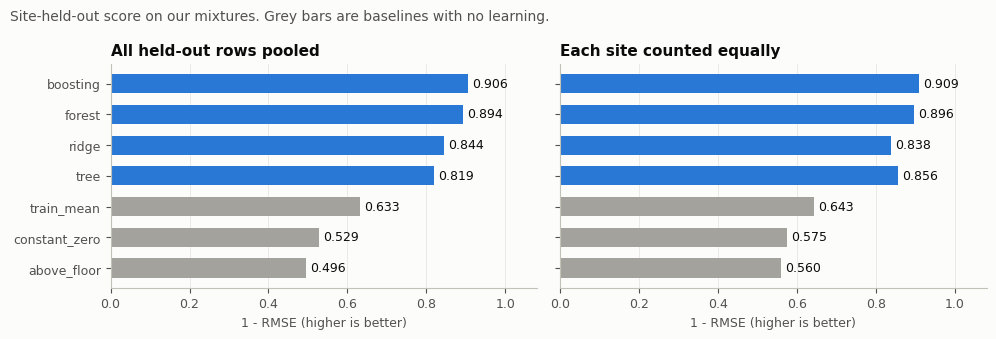

In [4]:
order = scores.sort_values("score")
colors = [BLUE if m in MODEL_NAMES else GREY for m in order["model"]]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, column, title in [(axes[0], "score", "All held-out rows pooled"),
                          (axes[1], "site_mean_score", "Each site counted equally")]:
    bars = ax.barh(order["model"], order[column], color=colors, height=0.62)
    ax.bar_label(bars, fmt="%.3f", padding=3, color="#0b0b0b")
    ax.set_xlim(0, 1.08); ax.set_xlabel("1 - RMSE (higher is better)"); ax.set_title(title)
    ax.grid(axis="y", visible=False)
fig.suptitle("Site-held-out score on our mixtures. Grey bars are baselines with no learning.",
             x=0.01, ha="left", fontsize=10, color=INK)
fig.tight_layout(); plt.show()

## Error by held-out site

In [5]:
by_site = result["by_site"]
rmse = by_site.pivot(index="site_id", columns="model", values="rmse")[list(BASELINE_NAMES) + list(MODEL_NAMES)]
rmse.insert(0, "site", site_names); rmse.insert(1, "n", by_site.groupby("site_id")["n"].first())
rmse

model,site,n,constant_zero,train_mean,above_floor,ridge,tree,forest,boosting
site_id,,,,,,,,,
1,1 Richards Bay,52134,0.5002,0.3844,0.5494,0.1615,0.2157,0.1225,0.1078
2,2 Durban,2976,0.4171,0.3121,0.3533,0.1583,0.1218,0.0801,0.0774
4,4 Bird Island,3168,0.0814,0.2982,0.6743,0.1845,0.0632,0.0590,0.0490
5,5 St Croix Island,16698,0.3226,0.2909,0.3388,0.1162,0.1039,0.0674,0.0613
7,7 St_Francis,3371,0.1068,0.2832,0.7186,0.1336,0.1234,0.1003,0.0802
9,9 Fish Hoek,294,0.5951,0.3691,0.3665,0.2316,0.3011,0.2660,0.2189
10,10 Sea Point,244,0.7146,0.4660,0.1679,0.1279,0.1002,0.0648,0.0605
13,13 Saldhana Bay,8867,0.6599,0.4491,0.3482,0.1798,0.1217,0.0743,0.0706


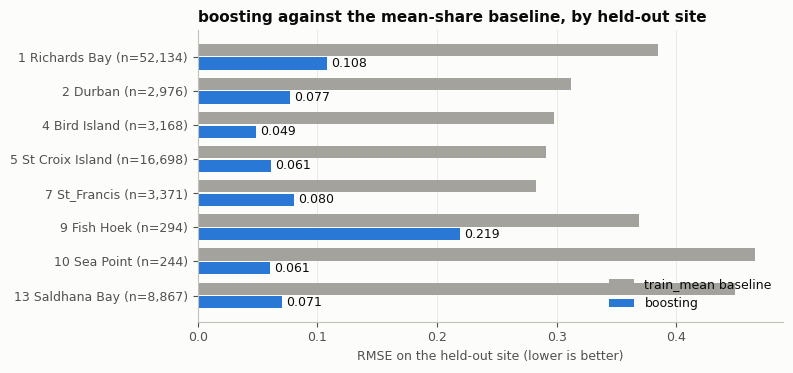

In [6]:
best = result["best"]
labels = [f"{site_names[s]} (n={rmse.loc[s, 'n']:,})" for s in rmse.index]
y = np.arange(len(rmse))
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(y - 0.2, rmse["train_mean"], height=0.36, color=GREY, label="train_mean baseline")
bars = ax.barh(y + 0.2, rmse[best], height=0.36, color=BLUE, label=best)
ax.bar_label(bars, fmt="%.3f", padding=3, color="#0b0b0b")
ax.set_yticks(y, labels); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlabel("RMSE on the held-out site (lower is better)")
ax.set_title(f"{best} against the mean-share baseline, by held-out site")
ax.legend(frameon=False, loc="lower right"); fig.tight_layout(); plt.show()

## Predicted against true share

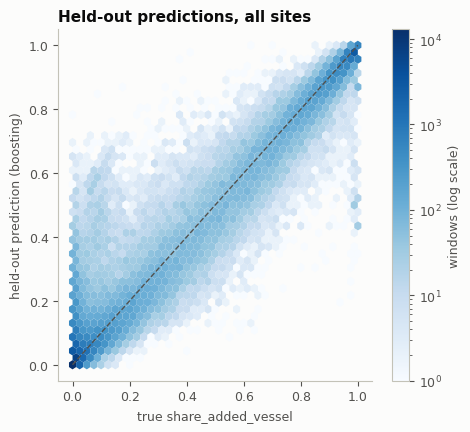

In [7]:
pred = result["predictions"]
fig, ax = plt.subplots(figsize=(4.8, 4.4))
hb = ax.hexbin(pred["share"], pred[f"pred_{best}"], gridsize=40, bins="log", cmap="Blues", mincnt=1, linewidths=0)
ax.plot([0, 1], [0, 1], color=INK, linewidth=1, linestyle="--")
ax.set_xlabel("true share_added_vessel"); ax.set_ylabel(f"held-out prediction ({best})")
ax.set_title("Held-out predictions, all sites"); ax.grid(False)
fig.colorbar(hb, ax=ax, label="windows (log scale)"); fig.tight_layout(); plt.show()

## Error by size of the share and by hidden minutes

model,boosting,train_mean,n
group,,,
"(-0.001, 0.01]",0.0782,0.2870,23767
"(0.01, 0.1]",0.1071,0.2521,21083
"(0.1, 0.3]",0.1153,0.1233,10906
"(0.3, 0.6]",0.1085,0.1839,9446
"(0.6, 0.9]",0.0813,0.4923,11659
"(0.9, 1.0]",0.0709,0.6930,10891


model,boosting,train_mean,n
group,,,
0,0.0917,0.3666,44001
1,0.0962,0.3680,43751


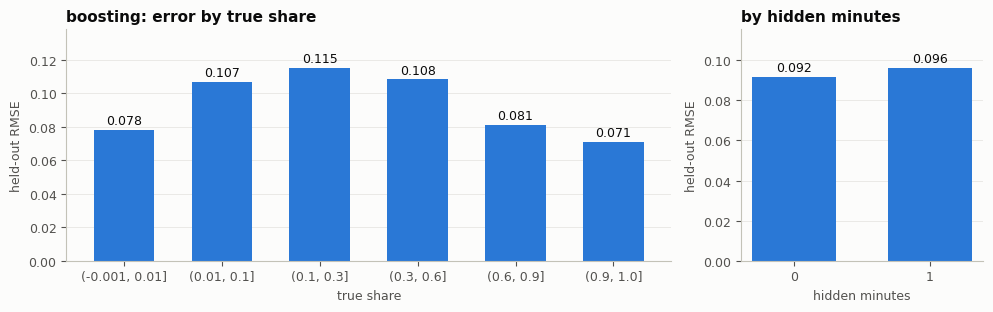

In [8]:
by_share = error_breakdown(pred, share_bin(pred["share"]), names=[best, "train_mean"])
by_missing = error_breakdown(pred, "missing_minutes", names=[best, "train_mean"])
display(by_share.pivot(index="group", columns="model", values="rmse").assign(n=by_share.groupby("group")["n"].first()))
display(by_missing.pivot(index="group", columns="model", values="rmse").assign(n=by_missing.groupby("group")["n"].first()))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), gridspec_kw={"width_ratios": [3, 1.2]})
for ax, frame, xlabel in [(axes[0], by_share, "true share"), (axes[1], by_missing, "hidden minutes")]:
    part = frame[frame["model"] == best]
    bars = ax.bar(part["group"].astype(str), part["rmse"], color=BLUE, width=0.62)
    ax.bar_label(bars, fmt="%.3f", padding=2, color="#0b0b0b")
    ax.set_xlabel(xlabel); ax.set_ylabel("held-out RMSE"); ax.grid(axis="x", visible=False)
    ax.set_ylim(0, part["rmse"].max() * 1.2)
axes[0].set_title(f"{best}: error by true share"); axes[1].set_title("by hidden minutes")
fig.tight_layout(); plt.show()

## Which features the forest uses

Impurity importance from the forest fit on all sites. It shows what the trees split on. It is not a held-out measure.

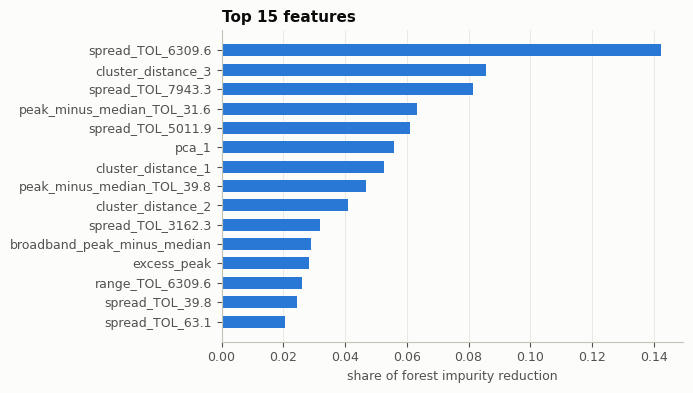

spread bands              0.4293
k-means distance          0.1846
peak_minus_median bands   0.1842
PCA                       0.0677
range bands               0.0664
broadband                 0.0305
neighbor background       0.0287
above_floor_share         0.0086
missing_minutes           0.0000
Name: importance, dtype: float64

In [9]:
importance = pd.Series(result["models"]["forest"].feature_importances_, index=result["feature_names"]).sort_values()
top = importance.tail(15)
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(top.index, top.values, color=BLUE, height=0.62)
ax.set_xlabel("share of forest impurity reduction"); ax.set_title("Top 15 features")
ax.grid(axis="y", visible=False); fig.tight_layout(); plt.show()
groups = {"peak_minus_median bands": "peak_minus_median_TOL", "range bands": "range_TOL", "spread bands": "spread_TOL",
          "broadband": "broadband_", "above_floor_share": "above_floor", "missing_minutes": "missing_",
          "PCA": "pca_", "k-means distance": "cluster_", "neighbor background": "ed_peak|ss_peak"}
pd.Series({k: importance[importance.index.str.contains(v)].sum() for k, v in groups.items()}, name="importance").sort_values(ascending=False)

## Trial runs for the open team questions

Boosting only, same folds. Each row changes one thing from the default run.

In [10]:
def trial(label, **kwargs):
    args = dict(windows=table["mixtures"], backgrounds=table["backgrounds"], max_per_site=None,
                models={"boosting": make_models()["boosting"]}, final_fit=False)
    args.update(kwargs)
    features = args.pop("features", table["features"])
    out = fit_site_held_out(features, table["shares"], table["site_ids"], **args)
    row = out["scores"].set_index("model").loc["boosting", ["score", "site_mean_score", "worst_site_rmse"]]
    return row.rename(label)

keep = [i for i, name in enumerate(result["feature_names"][:79]) if name != "above_floor_share"]
trials = pd.DataFrame([
    scores.set_index("model").loc["boosting", ["score", "site_mean_score", "worst_site_rmse"]].rename("default: 90 features, every training row"),
    trial("79 stateless features only", windows=None, backgrounds=None),
    trial("no neighbor background (PCA and k-means kept)", backgrounds=None),
    trial("no above_floor_share", features=table["features"][:, keep],
          feature_names=[result["feature_names"][i] for i in keep]),
    trial("cap 10,000 rows per training site", max_per_site=10000),
    trial("cap 3,000 rows per training site", max_per_site=3000),
])
trials

,score,site_mean_score,worst_site_rmse
"default: 90 features, every training row",0.9060,0.9093,0.2189
79 stateless features only,0.8577,0.8559,0.3393
no neighbor background (PCA and k-means kept),0.9065,0.9088,0.2172
no above_floor_share,0.9088,0.9105,0.2125
"cap 10,000 rows per training site",0.8995,0.9021,0.2332
"cap 3,000 rows per training site",0.8748,0.8930,0.2440


## Predictions for `Test.csv`

The final models are fit on every row of all 8 sites. `Test.csv` is only read here. `scripts/train_models.py` writes the same file and adds a line to `submissions/leaderboard_log.csv`.

,mean,std,min,50%,max
ridge,0.3280,0.2097,0.0000,0.3174,1.0000
tree,0.1876,0.2011,0.0003,0.1194,0.9347
forest,0.1827,0.1259,0.0042,0.1554,0.8043
boosting,0.1379,0.1341,0.0000,0.1017,0.7186


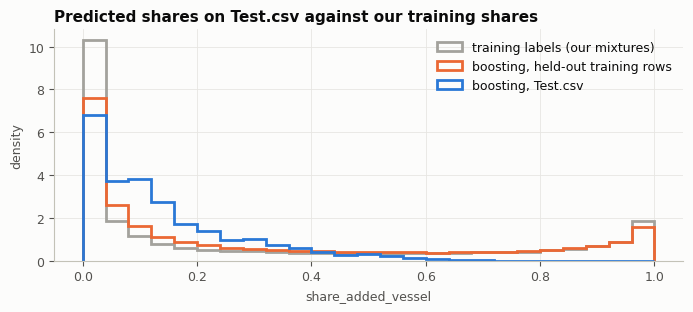

In [11]:
test = pd.read_csv(ROOT / "Test.csv")
test_windows = windows_from_frame(test)
test_features = window_features(test_windows)
test_share = pd.DataFrame({name: predict_share(result, test_features, test_windows, model=name) for name in MODEL_NAMES})
display(test_share.describe().T[["mean", "std", "min", "50%", "max"]])

bins = np.linspace(0, 1, 26)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(table["shares"], bins=bins, density=True, histtype="step", linewidth=2, color=GREY, label="training labels (our mixtures)")
ax.hist(pred[f"pred_{best}"], bins=bins, density=True, histtype="step", linewidth=2, color=ORANGE, label=f"{best}, held-out training rows")
ax.hist(test_share[best], bins=bins, density=True, histtype="step", linewidth=2, color=BLUE, label=f"{best}, Test.csv")
ax.set_xlabel("share_added_vessel"); ax.set_ylabel("density"); ax.set_title("Predicted shares on Test.csv against our training shares")
ax.legend(frameon=False); fig.tight_layout(); plt.show()

In [12]:
log_path = ROOT / "submissions" / "leaderboard_log.csv"
pd.read_csv(log_path) if log_path.exists() else "No submissions logged yet."

,date,file,model,cv_score,cv_site_mean_score,public_score,notes
0,2026-11-23,submission_boosting.csv,boosting,0.9060,0.9093,NaN,"90 features, every training row"


## What the runs show

- Boosting is best: `1 - RMSE` of 0.906 over all held-out rows and 0.909 with each site counted equally. The forest is close (0.894). Ridge reaches 0.844 and the single tree 0.819.
- All four models beat the baselines. Predicting the mean training share scores 0.633, predicting zero scores 0.529, and the above-floor share used directly scores 0.496.
- Fish Hoek is the hardest held-out site for every model (boosting RMSE 0.219, 294 windows). The other seven sites are between 0.049 and 0.108.
- A hidden minute costs almost nothing: RMSE 0.092 with none hidden and 0.096 with one. `Test.csv` also has 8 windows with two or three hidden minutes, which we never train on.
- The PCA and k-means columns matter. Without the fold-fitted columns the score drops from 0.906 to 0.858. The two neighbor-background columns add nothing on top of them (0.9065 without). Dropping `above_floor_share` changes little (0.909).
- Using every training row beats a per-site cap: 0.906 against 0.900 at 10,000 rows and 0.875 at 3,000.
- `score_added_vessel` is the predicted share. Its site-averaged ROC-AUC against "ship added or not" is 0.78. It is near 0.56 at Bird Island and St Francis, where most added ships are under 1% of the energy.

## Limits

- These are scores on our own mixtures. The leaderboard will be lower by however much our mixtures differ from the organizers'.
- Boosting predicts a mean share of 0.14 on `Test.csv` and nothing above 0.72. Our training shares pile up near 0 and near 1, because the same ship energy is added at loud and quiet sites. If the public score is far below 0.9, the label distribution is the first thing to check.
- The k-means distances carry 18% of the forest's importance. Two clusters are close to single sites, so part of that is site identity.
- Model settings are fixed. They were not tuned.
